# 04 · EMT-TF Expression — Raghavan 2021 PDAC  (unconditional final step)

The EMT-TF readout is produced regardless of gate outcome and is always the last notebook (here **04**,
following the Gate-2-GO / Gate-3-NA non-branching outcome). Score a broad EMT-TF panel — Snail/Zeb/Twist
**plus FOXC and PRRX families** — gated on detectable expression (VIM is NOT a TF and is excluded). Overlay
the two ends of the trajectory as a categorical thresholded-expresser overlay on a grey manifold.

In [ ]:
import os, sys, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = os.path.join(sys.exec_prefix, 'lib', 'R')  # scFates PPT -> rpy2 -> r-mgcv (conda prefix)
import numpy as np, pandas as pd, scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
adata = sc.read_h5ad(os.path.join(pth_out,'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 7758 | pseudotime 0.0 -> 9.73


### Score the EMT-TF panel; rank by pseudotime correlation, gated on detectable expression (>3%)

In [ ]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']  # VIM excluded (not a TF)
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn,1/3); late = tn >= np.quantile(tn,2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; rho,p = spearmanr(tn,x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early>df.mean_late,'EARLY(root)','LATE(terminus)')
df = df.sort_values('rho_vs_t'); print(df.to_string(index=False))
ok = df[df.frac_expr>0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']; late_tf = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.232       0.194      0.081    -0.237    EARLY(root)
 PRRX2      0.038       0.030      0.008    -0.128    EARLY(root)
 SNAI2      0.077       0.032      0.019    -0.082    EARLY(root)
  ZEB1      0.083       0.058      0.050    -0.072    EARLY(root)
 SNAI1      0.012       0.005      0.006    -0.027 LATE(terminus)
TWIST1      0.004       0.002      0.003    -0.014 LATE(terminus)
 PRRX1      0.005       0.002      0.003    -0.009 LATE(terminus)
  ZEB2      0.064       0.029      0.086     0.044 LATE(terminus)

derived pair: FOXC1 (early/root) <-> ZEB2 (late/terminus)


### EMT-TF expression figure (deliverable `expression.pdf`) — categorical overlay on grey, house 3.5×1.5

FOXC1: 23.2% expressing; 450 shown; mean pt shown=0.40
ZEB2: 6.4% expressing; 124 shown; mean pt shown=0.80
saved expression.pdf


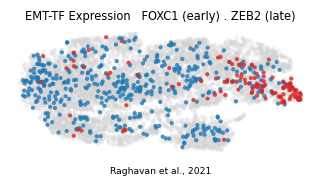

In [ ]:
xl = adata.obsm['X_umap']; xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [early_tf,late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g:_vec(g)>thr[g] for g in [early_tf,late_tf]}
order = sorted([early_tf,late_tf], key=lambda g:-int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    sc.pl.umap(adata[sel[g]].copy(), na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {early_tf} (early) . {late_tf} (late)', size=7.5)
ax.text(.5,-.14,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in [early_tf,late_tf]:
    print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} shown; mean pt shown={tn[sel[g]].mean():.2f}')
print('saved expression.pdf')